In [ ]:
import os
import random
import sys

EXPERIMENT_SEED = 7
_pythonhashseed_at_kernel_start = os.environ.get("PYTHONHASHSEED")
_required_env = {
    "PYTHONHASHSEED": str(EXPERIMENT_SEED),
    "CUDA_DEVICE_ORDER": "PCI_BUS_ID",
    "CUDA_VISIBLE_DEVICES": "0",
    "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
    "NVIDIA_TF32_OVERRIDE": "0",
    "OMP_NUM_THREADS": "12",
    "MKL_NUM_THREADS": "12",
}

_premature_imports = sorted(
    name for name in ("numpy", "pandas", "torch", "stable_baselines3", "finrl")
    if name in sys.modules
)
if _premature_imports:
    raise RuntimeError(
        "Restart the kernel and run this cell first; already imported: "
        + ", ".join(_premature_imports)
    )
for _name, _value in _required_env.items():
    os.environ[_name] = _value

random.seed(EXPERIMENT_SEED)
import numpy as np
import pandas as pd
import torch

np.random.seed(EXPERIMENT_SEED)
torch.manual_seed(EXPERIMENT_SEED)
torch.cuda.manual_seed_all(EXPERIMENT_SEED)
torch.set_num_threads(12)
torch.set_num_interop_threads(12)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.set_float32_matmul_precision("highest")
torch.use_deterministic_algorithms(True)

if not torch.cuda.is_available():
    raise RuntimeError("1270b requires an NVIDIA GPU, but torch.cuda.is_available() is False")
torch.cuda.set_device(0)

assert torch.are_deterministic_algorithms_enabled()
assert not torch.backends.cudnn.benchmark
assert torch.backends.cudnn.deterministic
assert not torch.backends.cuda.matmul.allow_tf32
assert not torch.backends.cudnn.allow_tf32
assert torch.get_num_threads() == 12
assert all(os.environ[name] == value for name, value in _required_env.items())

print("1270b S1 corrected-4C deterministic GPU bootstrap")
print("seed =", EXPERIMENT_SEED)
print("device =", torch.device("cuda:0"), torch.cuda.get_device_name(0))
print("PyTorch/CUDA =", torch.__version__, torch.version.cuda)
print("environment =", _required_env)
if _pythonhashseed_at_kernel_start != str(EXPERIMENT_SEED):
    print(
        "WARNING: PYTHONHASHSEED was not set to this seed when the Jupyter kernel "
        "started. The cell sets it for child processes, but strict interpreter-level "
        "hash reproducibility requires launching/restarting the kernel with "
        f"PYTHONHASHSEED={EXPERIMENT_SEED}."
    )


1270b S1 corrected-4C deterministic GPU bootstrap
seed = 7
device = cuda:0 NVIDIA GeForce RTX 2080 Ti
PyTorch/CUDA = 2.9.1+cu128 12.8
environment = {'PYTHONHASHSEED': '7', 'CUDA_DEVICE_ORDER': 'PCI_BUS_ID', 'CUDA_VISIBLE_DEVICES': '0', 'CUBLAS_WORKSPACE_CONFIG': ':4096:8', 'NVIDIA_TF32_OVERRIDE': '0', 'OMP_NUM_THREADS': '12', 'MKL_NUM_THREADS': '12'}


<a id='1'></a>
# Part 2. Getting Started- Load Python Packages


In [ ]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path(os.environ.get("RGPPO_ROOT", str(Path.cwd())))
while not (PROJECT_ROOT / "data" / "new_version_2026").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

os.environ["OMP_NUM_THREADS"] = "12"
os.environ["MKL_NUM_THREADS"] = "12"

print("OMP_NUM_THREADS =", os.environ["OMP_NUM_THREADS"])
print("MKL_NUM_THREADS =", os.environ["MKL_NUM_THREADS"])

import numpy as np
import pandas as pd
import torch
print("PyTorch CPU threads:", torch.get_num_threads())


OMP_NUM_THREADS = 12
MKL_NUM_THREADS = 12
PyTorch CPU threads: 12


<a id='1.1'></a>
## 2.1. Install all the packages through FinRL library


In [ ]:
%load_ext autoreload
%autoreload 2



<a id='1.2'></a>
## 2.2. Check if the additional packages needed are present, if not 


<a id='1.3'></a>
## 2.3. Import Packages


In [ ]:
import warnings
warnings.filterwarnings("ignore")


In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import datetime
from pathlib import Path

%matplotlib inline

from finrl.config import INDICATORS
from finrl.meta.preprocessor.preprocessors import FeatureEngineer
from finrl.plot import backtest_stats, backtest_plot, get_daily_return, get_baseline
from scripts.Tail_GAE.src.mda_ppo_audit import MDAAuditConfig, audit_mda_ppo_run
from scripts.Tail_GAE.src.notebook_config import (
    DATA_FILE, DJI_FILE, PPO_MODEL_KWARGS, PPO_TIMESTEPS, get_experiment_config,
)
from scripts.Tail_GAE.src.tail_gae_data import load_tail_data
from scripts.Tail_GAE.src.tail_gae_rolling_runner import TailGAERollingRunner

from pprint import pprint


<a id='1.4'></a>
## 2.4. Create Folders


In [ ]:
import os
from finrl.main import check_and_make_directories
from finrl.config import (DATA_SAVE_DIR, TRAINED_MODEL_DIR, TENSORBOARD_LOG_DIR, RESULTS_DIR, INDICATORS, 
                          TRAIN_START_DATE, TRAIN_END_DATE, TEST_START_DATE, TEST_END_DATE, TRADE_START_DATE, TRADE_END_DATE)

check_and_make_directories([DATA_SAVE_DIR, TRAINED_MODEL_DIR, TENSORBOARD_LOG_DIR, RESULTS_DIR])

<a id='2'></a>
# Part 3. Download Data
Yahoo Finance is a website that provides stock data, financial news, financial reports, etc. All the data provided by Yahoo Finance is free.
* FinRL uses a class **YahooDownloader** to fetch data from Yahoo Finance API
* Call Limit: Using the Public API (without authentication), you are limited to 2,000 requests per hour per IP (or up to a total of 48,000 requests a day).


In [7]:
TRAIN_START_DATE = '2013-04-01'
TRAIN_END_DATE = '2024-12-31'
TEST_START_DATE = '2025-01-01'
TEST_END_DATE = '2026-06-01'


DATA_FILE = PROJECT_ROOT / "data/new_version_2026/data_30_20100101_20260601.csv"
DJI_FILE = PROJECT_ROOT / "data/DJI_2013_2026.csv"

# df = YahooDownloader(start_date = TRAIN_START_DATE,
#                      end_date = TEST_END_DATE,
#                      ticker_list = DOW_30_TICKER).fetch_data()
df = pd.read_csv(DATA_FILE)
df.head()


,date,close,high,low,open,volume,tic,day
0,2010-01-04,6.406482,6.421151,6.357688,6.389120,493729600,AAPL,0
1,2010-01-04,38.748535,38.849231,37.969805,38.016797,5277400,AMGN,0
2,2010-01-04,6.695000,6.830500,6.657000,6.812500,151998000,AMZN,0
3,2010-01-04,32.380951,32.523389,31.961551,32.293908,6894300,AXP,0
4,2010-01-04,43.777561,43.941200,42.702213,43.419113,6186700,BA,0


# Part 4: Preprocess Data
Data preprocessing is a crucial step for training a high quality machine learning model. We need to check for missing data and do feature engineering in order to convert the data into a model-ready state.
* Add technical indicators. In practical trading, various information needs to be taken into account, for example the historical stock prices, current holding shares, technical indicators, etc. In this article, we demonstrate two trend-following technical indicators: MACD and RSI.
* Add turbulence index. Risk-aversion reflects whether an investor will choose to preserve the capital. It also influences one's trading strategy when facing different market volatility level. To control the risk in a worst-case scenario, such as financial crisis of 2007–2008, FinRL employs the financial turbulence index that measures extreme asset price fluctuation.


In [ ]:
fe = FeatureEngineer(use_technical_indicator=True,
                     tech_indicator_list = INDICATORS,
                     use_turbulence=True,
                     user_defined_feature = False)

processed = fe.preprocess_data(df)
processed = processed.copy()
processed = processed.fillna(0)
processed = processed.replace(np.inf,0)

Successfully added technical indicators


Successfully added turbulence index


<a id='4'></a>
# Part 5. Design Environment
Considering the stochastic and interactive nature of the automated stock trading tasks, a financial task is modeled as a **Markov Decision Process (MDP)** problem. The training process involves observing stock price change, taking an action and reward's calculation to have the agent adjusting its strategy accordingly. By interacting with the environment, the trading agent will derive a trading strategy with the maximized rewards as time proceeds.

Our trading environments, based on OpenAI Gym framework, simulate live stock markets with real market data according to the principle of time-driven simulation.

The action space describes the allowed actions that the agent interacts with the environment. Normally, action a includes three actions: {-1, 0, 1}, where -1, 0, 1 represent selling, holding, and buying one share. Also, an action can be carried upon multiple shares. We use an action space {-k,…,-1, 0, 1, …, k}, where k denotes the number of shares to buy and -k denotes the number of shares to sell. For example, "Buy 10 shares of AAPL" or "Sell 10 shares of AAPL" are 10 or -10, respectively. The continuous action space needs to be normalized to [-1, 1], since the policy is defined on a Gaussian distribution, which needs to be normalized and symmetric.


In [ ]:
EXPERIMENT_ID = "1270b"
exp_cfg = get_experiment_config(EXPERIMENT_ID, EXPERIMENT_SEED)
tail_data = load_tail_data(p_tail=float(exp_cfg["p_tail"]))

# 1270b/S1 (v4.13 P0, corrected-4C): 1270b 配置 + 方向标签生命周期修复
# （每步先清零再写当日超限集合; 代码级修复, 无配置键）。
# while policy observation stays at 301 dims and the 4C direct loss is enabled.
processed = tail_data["processed"]
env_kwargs = dict(tail_data["env_kwargs"])
stock_dimension = int(env_kwargs["stock_dim"])
state_space = int(env_kwargs["state_space"])
risk_state_names = list(exp_cfg["risk_state_names"])
internal_risk_fields = list(exp_cfg["internal_risk_fields"])
policy_risk_fields = list(exp_cfg["policy_risk_fields"])
assert risk_state_names == []
assert len(internal_risk_fields) == 7
assert policy_risk_fields == []
assert float(exp_cfg["direct_penalty_beta"]) == 0.03
assert bool(exp_cfg["use_mu_ref"]) is True
assert bool(exp_cfg["direct_ref_exec_aligned"]) is True
policy_state_space = state_space

print(f"Stock Dimension: {stock_dimension}")
print(f"Base State Space: {state_space}")
print(f"Internal Risk Wrapper Fields: {internal_risk_fields}")
print("Policy Risk Observation Fields: []")
print(f"Policy Observation Dimension: {policy_state_space}")


Successfully added technical indicators


Successfully added turbulence index


Stock Dimension: 30
Base State Space: 301
Internal Risk Wrapper Fields: ['current_drawdown', 'running_max_drawdown', 'drawdown_delta', 'downside_volatility_20', 'gross_exposure', 'mkt_ew_10', 'mkt_ew_5']
Policy Risk Observation Fields: []
Policy Observation Dimension: 301


In [ ]:
# Unified Tail-GAE base-environment contract, including per-stock cost arrays.
env_kwargs = dict(tail_data["env_kwargs"])
print(env_kwargs)


{'stock_dim': 30, 'hmax': 100, 'initial_amount': 1000000, 'buy_cost_pct': [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001], 'sell_cost_pct': [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001], 'tech_indicator_list': ['macd', 'boll_ub', 'boll_lb', 'rsi_30', 'cci_30', 'dx_30', 'close_30_sma', 'close_60_sma'], 'turbulence_threshold': None, 'reward_scaling': 0.0001, 'state_space': 301, 'action_space': 30}


<a id='5'></a>
# Part 6: Implement DRL Algorithms
* The implementation of the DRL algorithms are based on **OpenAI Baselines** and **Stable Baselines**. Stable Baselines is a fork of OpenAI Baselines, with a major structural refactoring, and code cleanups.
* FinRL library includes fine-tuned standard DRL algorithms, such as DQN, DDPG,
Multi-Agent DDPG, PPO, SAC, A2C and TD3. We also allow users to
design their own DRL algorithms by adapting these DRL algorithms.

* In this notebook, we are training and validating 3 agents (A2C, PPO, DDPG) using Rolling-window Ensemble Method ([reference code](https://github.com/AI4Finance-LLC/Deep-Reinforcement-Learning-for-Automated-Stock-Trading-Ensemble-Strategy-ICAIF-2020/blob/80415db8fa7b2179df6bd7e81ce4fe8dbf913806/model/models.py#L92))


In [ ]:
rebalance_window = 63
validation_window = 63
rolling_window_count = 4
print("1270b S1 unified-1200 control rolling windows:", rolling_window_count)


1270b S1 unified-1200 control rolling windows: 4


In [ ]:
ppo_model_kwargs = dict(PPO_MODEL_KWARGS)
ppo_model_kwargs["use_mu_ref"] = bool(exp_cfg["use_mu_ref"])
ppo_model_kwargs["grad_diag"] = True  # v4.13 P0: 训练期审计仪表（g_C/余弦/裁剪范数）
assert ppo_model_kwargs["use_mu_ref"] is True
ppo_timesteps = PPO_TIMESTEPS
print("PPO model kwargs:", ppo_model_kwargs)
print("PPO timesteps/window:", ppo_timesteps)


PPO model kwargs: {'ent_coef': 0.01, 'n_steps': 1024, 'batch_size': 256, 'learning_rate': 0.0001, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.15, 'target_kl': 0.015, 'max_grad_norm': 0.5, 'policy_kwargs': {'net_arch': {'pi': [256, 256], 'vf': [256, 256]}}, 'use_mu_ref': True, 'grad_diag': True}
PPO timesteps/window: 40000


In [ ]:
seed = EXPERIMENT_SEED
print("seed =", seed)
print("CUBLAS_WORKSPACE_CONFIG =", os.environ["CUBLAS_WORKSPACE_CONFIG"])
print("S1 reward path = 1200 mda(lambda=0), component stats fit on window 1 then freeze")
print("S1 observation path = fit 301 dims on window 1, then freeze")
print("S1 mechanisms = internal risk wrapper √, policy risk state ×, direct loss √")


seed = 7
CUBLAS_WORKSPACE_CONFIG = :4096:8
S1 reward path = 1200 mda(lambda=0), component stats fit on window 1 then freeze
S1 observation path = fit 301 dims on window 1, then freeze
S1 mechanisms = internal risk wrapper √, policy risk state ×, direct loss √


In [ ]:
NOTEBOOK_PATH = PROJECT_ROOT / "ultimate_experiment" / "1270b Tail_GAE" / f"Tail_GAE_1270b_s1_corrected_4c_seed_{seed}.ipynb"

mda_audit_config = MDAAuditConfig(
    seed=seed,
    lambda_value=0.0,
    reward_mode="mda",
    use_risk_observation=False,
    output_root=Path(exp_cfg["output_root"]),
    data_path=DATA_FILE,
    notebook_path=NOTEBOOK_PATH,
    dji_path=DJI_FILE,
    deterministic=True,
    log_freq=1024,
    artifact_id=f"1270b {exp_cfg['experiment_name'].lower()}",
    experiment_name=exp_cfg["experiment_name"].lower(),
    run_directory_layout="seed_timestamp",
    normalization_config={
        "enabled": True,
        "normalize_observations": True,
        "normalize_rewards": False,
        "fit_once_on_meta_train": True,
        "normalize_mda_components": True,
        "fit_mda_components_once_on_meta_train": True,
    },
    risk_observation_fields=policy_risk_fields,
    max_windows=rolling_window_count,
    allow_ineligible_backtest=True,
    extra={
        "v47_stage": "B2",
        "ablation": "S1_corrected_4c",
        "reward_protocol": "1200_mda_lambda0_return_component_first_window_frozen",
        "observation_protocol": "1200_first_window_base_stats_frozen",
        "strict_kernel_bootstrap": True,
        "required_cublas_workspace_config": ":4096:8",
        "internal_risk_fields": internal_risk_fields,
        "policy_risk_fields": policy_risk_fields,
        "direct_penalty_beta": float(exp_cfg["direct_penalty_beta"]),
        "direct_penalty_ref": float(exp_cfg["direct_penalty_ref"]),
        "compute_direct_diagnostics": True,
        "use_mu_ref": bool(exp_cfg["use_mu_ref"]),
        "direct_ref_exec_aligned": bool(exp_cfg["direct_ref_exec_aligned"]),
    },
)

mda_audit_result = audit_mda_ppo_run(
    config=mda_audit_config,
    processed=processed,
    raw_data=df,
    env_kwargs=env_kwargs,
    train_period=(exp_cfg["train_start"], exp_cfg["train_end"]),
    val_test_period=(exp_cfg["val_test_start"], exp_cfg["val_test_end"]),
    rebalance_window=rebalance_window,
    validation_window=validation_window,
    ppo_model_kwargs=ppo_model_kwargs,
    ppo_timesteps=ppo_timesteps,
    runner_cls=TailGAERollingRunner,
    runner_kwargs={
        "tail_alpha": 0.0,
        "i_by_date": tail_data["i_by_date"],
        "risk_state_names": [],
        "internal_risk_fields": internal_risk_fields,
        "policy_risk_fields": policy_risk_fields,
        "signal_table": tail_data["signal_table"],
        "worst20_by_date": tail_data["worst20_by_date"],
        "ew_by_date": tail_data["ew_by_date"],
        "ge_penalty_beta": 0.0,
        "ge_penalty_ref": 0.85,
        "ge_penalty_mode": "total",
        "tilt_shift": False,
        "expected_risk_observation_fields": policy_risk_fields,
        "direct_penalty_beta": float(exp_cfg["direct_penalty_beta"]),
        "direct_penalty_ref": float(exp_cfg["direct_penalty_ref"]),
        "compute_direct_diagnostics": True,
        "direct_ref_exec_aligned": bool(exp_cfg["direct_ref_exec_aligned"]),
        "trade_log": True,
    },
)

observation_contract = dict(mda_audit_result.runner_result["observation"])
assert observation_contract["use_risk_observation"] is False
assert observation_contract["base_observation_dim"] == state_space
assert observation_contract["risk_observation_dim"] == 0
assert observation_contract["risk_observation_fields"] == []
assert observation_contract["policy_observation_dim"] == policy_state_space == 301

print("Actual observation contract:")
pprint(observation_contract)
df_summary = mda_audit_result.df_summary
print("audit run_dir:", mda_audit_result.run_dir)
display(df_summary)


============Start Single PPO Strategy============
run_id: rolling
experiment_name: tail_gae_v4_13_corrected4c
reward_mode: mda
ppo_timesteps: 40000
seed(s): [7]
risk_wrapper: enabled=True, internal_dim=7, internal_fields=['current_drawdown', 'running_max_drawdown', 'drawdown_delta', 'downside_volatility_20', 'gross_exposure', 'mkt_ew_10', 'mkt_ew_5']
policy_risk_observation: enabled=False, dim=0, fields=[]
window_index: 0
iteration: 126
window_label: iter_126
seed: 7
======PPO Training========
======Model training for window: iter_126 (2013-04-01 -> 2025-01-02)
{'ent_coef': 0.01, 'n_steps': 1024, 'batch_size': 256, 'learning_rate': 0.0001, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.15, 'target_kl': 0.015, 'max_grad_norm': 0.5, 'use_mu_ref': True, 'grad_diag': True}
Using cuda device


Logging to <results_root>/Tail_GAE/1270b/seed_7/20261018_203312/scripts/MDA_PPO/runs/tensorboard/ppo_rolling_iter_126_seed_7_1


-----------------------------
| time/              |      |
|    fps             | 227  |
|    iterations      | 1    |
|    time_elapsed    | 4    |
|    total_timesteps | 1024 |
-----------------------------


-----------------------------------------
| time/                   |             |
|    fps                  | 207         |
|    iterations           | 2           |
|    time_elapsed         | 9           |
|    total_timesteps      | 2048        |
| train/                  |             |
|    approx_kl            | 0.017089259 |
|    clip_fraction        | 0.318       |
|    clip_range           | 0.15        |
|    direct_loss          | 9.86        |
|    entropy_loss         | -42.6       |
|    explained_variance   | 0.0352      |
|    grad_cos_pc          | -0.071      |
|    grad_logstd_ent      | 0.0548      |
|    grad_logstd_pg       | 0.438       |
|    grad_mu_pc           | 0.463       |
|    grad_mu_pg           | 4.04        |
|    grad_norm_post       | 0.5         |
|    grad_norm_pre        | 12.5        |
|    hinge_active         | 1           |
|    kl_early_stops       | 0           |
|    learning_rate        | 0.0001      |
|    loss                 | 1.68  

-----------------------------------------
| time/                   |             |
|    fps                  | 203         |
|    iterations           | 3           |
|    time_elapsed         | 15          |
|    total_timesteps      | 3072        |
| train/                  |             |
|    approx_kl            | 0.011963602 |
|    clip_fraction        | 0.207       |
|    clip_range           | 0.15        |
|    direct_loss          | 8.97        |
|    entropy_loss         | -42.6       |
|    explained_variance   | 0.118       |
|    grad_cos_pc          | -0.206      |
|    grad_logstd_ent      | 0.0548      |
|    grad_logstd_pg       | 0.487       |
|    grad_mu_pc           | 0.559       |
|    grad_mu_pg           | 3.95        |
|    grad_norm_post       | 0.5         |
|    grad_norm_pre        | 5.7         |
|    hinge_active         | 1           |
|    kl_early_stops       | 0           |
|    learning_rate        | 0.0001      |
|    loss                 | 3.01  

...

[risk_state_env] current_drawdown: mean=-0.882513 std=0.121923 min=-1.000000 max=-0.260636 (iteration=40)
[risk_state_env] running_max_drawdown: mean=-0.671702 std=0.176111 min=-1.000000 max=-0.260636 (iteration=40)
[risk_state_env] drawdown_delta: mean=0.000306 std=0.078927 min=-0.744578 max=1.109947 (iteration=40)
[risk_state_env] downside_volatility_20: mean=0.106866 std=0.074243 min=0.000000 max=1.021167 (iteration=40)
[risk_state_env] gross_exposure: mean=0.755848 std=0.395757 min=-0.947869 max=1.000000 (iteration=40)
[risk_state_env] mkt_ew_10: mean=0.006959 std=0.029510 min=-0.247178 max=0.210688 (iteration=40)
[risk_state_env] mkt_ew_5: mean=0.003481 std=0.021565 min=-0.182747 max=0.189776 (iteration=40)


======PPO Validation from: 2025-10-06 to 2026-01-06


hit end!
Validation account_value path: <results_root>/Tail_GAE/1270b/seed_7/20261018_203312/scripts/MDA_PPO/runs/rolling/tail_gae_v4_13_corrected4c/account_value_validation_tail_gae_v4_13_corrected4c_iter_315.csv
======Trading from: 2026-01-05 to 2026-04-08
Used Model: PPO
Trade account_value path: <results_root>/Tail_GAE/1270b/seed_7/20261018_203312/scripts/MDA_PPO/runs/rolling/tail_gae_v4_13_corrected4c/account_value_trade_tail_gae_v4_13_corrected4c_iter_315.csv
Runner summary path: <results_root>/Tail_GAE/1270b/seed_7/20261018_203312/scripts/MDA_PPO/runs/rolling/tail_gae_v4_13_corrected4c/runner_summary.csv
Single PPO Strategy took: 4 window(s)


Actual observation contract:
{'base_observation_dim': 301,
 'phase9_observation_dim': 0,
 'phase9_observation_fields': [],
 'policy_observation_dim': 301,
 'risk_observation_dim': 0,
 'risk_observation_fields': [],
 'use_risk_observation': False}
audit run_dir: <results_root>/Tail_GAE/1270b/seed_7/20261018_203312


,run_id,experiment_name,reward_mode,lambda_value,seed,window_index,iteration,window_label,model_name,ppo_timesteps,validation_account_value_path,trade_account_value_path,quality_gate_status,quality_gate_reason,use_risk_observation,base_observation_dim,risk_observation_dim,risk_observation_fields,policy_observation_dim
0,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,0,126,iter_126,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301
1,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,1,189,iter_189,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301
2,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,2,252,iter_252,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301
3,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,3,315,iter_315,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301


In [15]:
df_summary


,run_id,experiment_name,reward_mode,lambda_value,seed,window_index,iteration,window_label,model_name,ppo_timesteps,validation_account_value_path,trade_account_value_path,quality_gate_status,quality_gate_reason,use_risk_observation,base_observation_dim,risk_observation_dim,risk_observation_fields,policy_observation_dim
0,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,0,126,iter_126,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301
1,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,1,189,iter_189,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301
2,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,2,252,iter_252,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301
3,rolling,tail_gae_v4_13_corrected4c,mda,0.0,7,3,315,iter_315,ppo,40000,/Tail_GAE/1270b/see...,/Tail_GAE/1270b/see...,disabled,quality gate disabled,False,301,0,[],301


df_summary


<a id='6'></a>
# Part 7: Backtest Our Strategy
Backtesting plays a key role in evaluating the performance of a trading strategy. Automated backtesting tool is preferred because it reduces the human error. We usually use the Quantopian pyfolio package to backtest our trading strategies. It is easy to use and consists of various individual plots that provide a comprehensive image of the performance of a trading strategy.


In [ ]:
unique_trade_date = processed[(processed.date > TEST_START_DATE)&(processed.date <= TEST_END_DATE)].date.unique()
df_trade_date = pd.DataFrame({'datadate':unique_trade_date})


In [ ]:
run_dir = mda_audit_result.run_dir
if mda_audit_result.account_value is None:
    df_account_value_mda = pd.DataFrame(columns=["date", "account_value"])
else:
    df_account_value_mda = mda_audit_result.account_value.copy()

if df_account_value_mda.empty or "account_value" not in df_account_value_mda.columns or df_account_value_mda["account_value"].dropna().empty:
    print("Tail_GAE account values unavailable; skipping Sharpe computation.")
    sharpe = float("nan")
else:
    sharpe = (252 ** 0.5) * df_account_value_mda.account_value.pct_change(1).mean() / df_account_value_mda.account_value.pct_change(1).std()
    print('Sharpe Ratio of MDA_PPO: ', sharpe)


Sharpe Ratio of MDA_PPO:  1.4477737260129053


In [ ]:
# 如果文件里有 account_value 列，就直接用它
if df_account_value_mda.empty or "account_value" not in df_account_value_mda.columns:
    df_result_mda = pd.DataFrame(columns=["mda_ppo"])
    df_result_mda.index.name = "date"
else:
    df_result_mda = pd.DataFrame({
        "date": df_account_value_mda["date"],
        "mda_ppo": df_account_value_mda["account_value"],
    })
    df_result_mda = df_result_mda.set_index("date")


In [19]:
df_account_value_mda.head()


,date,account_value
0,2025-04-04,1.000000e+06
1,2025-04-07,1.000078e+06
2,2025-04-08,1.000008e+06
3,2025-04-09,1.001340e+06
4,2025-04-10,1.000736e+06


In [20]:
df_account_value_mda.head()


,date,account_value
0,2025-04-04,1.000000e+06
1,2025-04-07,1.000078e+06
2,2025-04-08,1.000008e+06
3,2025-04-09,1.001340e+06
4,2025-04-10,1.000736e+06


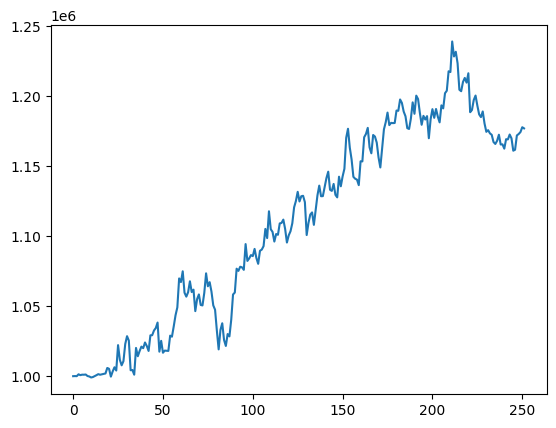

In [ ]:
%matplotlib inline
if df_account_value_mda.empty or "account_value" not in df_account_value_mda.columns or df_account_value_mda["account_value"].dropna().empty:
    print("No account value data available for plot; skipping.")
else:
    df_account_value_mda.account_value.plot()


<a id='6.1'></a>
## 7.1 BackTestStats
pass in df_account_value, this information is stored in env class


In [ ]:
print("==============Get Backtest Results===========")
now = datetime.datetime.now().strftime('%Y%m%d-%Hh%M')

if mda_audit_result.mda_stats is None:
    print("mda_stats unavailable; skipping stats display.")
else:
    perf_stats_all = mda_audit_result.mda_stats.copy()
    display(perf_stats_all)

==============Get Backtest Results===========


,0
Annual return,0.177864
Cumulative returns,0.177099
Annual volatility,0.117888
Sharpe ratio,1.447774
Calmar ratio,2.823732
Stability,0.908327
Max drawdown,-0.062989
Omega ratio,1.276710
Sortino ratio,2.193041
Skew,-0.068400


In [ ]:
print("==============Get Baseline Stats===========")
if mda_audit_result.baseline is None or mda_audit_result.baseline_stats is None:
    print("Baseline data unavailable; skipping baseline stats.")
else:
    df_dji_ = mda_audit_result.baseline.copy()
    stats = mda_audit_result.baseline_stats.copy()
    display(stats)

==============Get Baseline Stats===========


,0
Annual return,0.216780
Cumulative returns,0.215833
Annual volatility,0.153633
Sharpe ratio,1.353141
Calmar ratio,2.166638
Stability,0.772204
Max drawdown,-0.100054
Omega ratio,1.284542
Sortino ratio,2.314066
Skew,2.011085


In [ ]:
output_path = run_dir / "audit/results/tail_gae_stats.csv"
print("Tail_GAE stats :", output_path)

Tail_GAE stats : <results_root>/Tail_GAE/1270b/seed_7/20261018_203312/audit/results/tail_gae_stats.csv


In [ ]:
if mda_audit_result.baseline is None:
    print("Baseline data unavailable; skipping DJI export.")
else:
    df_dji = mda_audit_result.baseline[["date", "dji"]].copy()
    print("df_dji: ", df_dji)
    df_dji = df_dji.set_index("date")
    print("df_dji: ", df_dji)
    df_dji.to_csv(run_dir / "audit/results/df_dji_indexed.csv")


df_dji:             date           dji
0    2025-04-04  1.000000e+06
1    2025-04-07  9.908845e+05
2    2025-04-08  9.825324e+05
3    2025-04-09  1.059862e+06
4    2025-04-10  1.033376e+06
..          ...           ...
247  2026-03-31  1.209492e+06
248  2026-04-01  1.215344e+06
249  2026-04-02  1.213750e+06
250  2026-04-06  1.218062e+06
251  2026-04-07  1.215833e+06

[252 rows x 2 columns]
df_dji:                       dji
date                    
2025-04-04  1.000000e+06
2025-04-07  9.908845e+05
2025-04-08  9.825324e+05
2025-04-09  1.059862e+06
2025-04-10  1.033376e+06
...                  ...
2026-03-31  1.209492e+06
2026-04-01  1.215344e+06
2026-04-02  1.213750e+06
2026-04-06  1.218062e+06
2026-04-07  1.215833e+06

[252 rows x 1 columns]


<a id='6.2'></a>
## 7.2 BackTestPlot


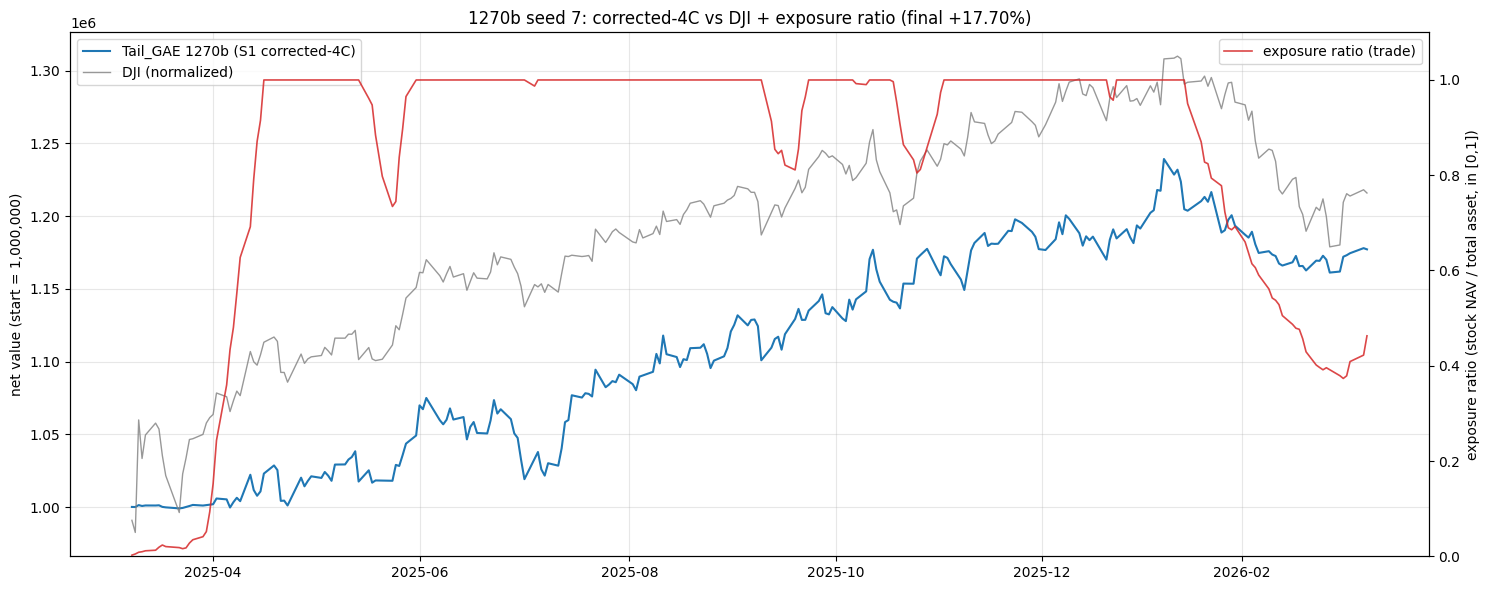

In [ ]:
# 1270b S1: internal risk wrapper + direct loss + 301-dim policy + complete 1200 normalization.
import glob

account_file = sorted(glob.glob(str(run_dir / "audit" / "results" / "df_account_value_*.csv")))[0]
acct = pd.read_csv(account_file, parse_dates=["date"]).set_index("date")["account_value"]
dji = pd.read_csv(run_dir / "audit" / "results" / "df_dji.csv", parse_dates=["date"])
dji = dji.set_index("date")["dji"]

exposure_parts = []
for window_label in ("iter_126", "iter_189", "iter_252", "iter_315"):
    trade_file = run_dir / "tail_mechanism" / "trade" / f"{window_label}.csv"
    trade = pd.read_csv(trade_file, parse_dates=["date"])
    exposure_parts.append(trade[["date", "gross_exposure"]])
exposure = (
    pd.concat(exposure_parts)
    .drop_duplicates("date")
    .sort_values("date")
    .set_index("date")["gross_exposure"]
)

acct_plot, exposure_plot = acct.align(exposure, join="inner")
dji_plot = dji.reindex(acct_plot.index)
final_return = acct_plot.iloc[-1] / acct_plot.iloc[0] - 1.0

fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.plot(acct_plot.index, acct_plot.values, label="Tail_GAE 1270b (S1 corrected-4C)", linewidth=1.5, color="tab:blue")
ax1.plot(dji_plot.index, dji_plot.values, label="DJI (normalized)", linewidth=1.0, alpha=0.8, color="tab:gray")
ax1.set_ylabel("net value (start = 1,000,000)")
ax1.set_title(f"1270b seed {seed}: corrected-4C vs DJI + exposure ratio (final {final_return:+.2%})")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(exposure_plot.index, exposure_plot.values, label="exposure ratio (trade)", linewidth=1.2, color="tab:red", alpha=0.85)
ax2.set_ylabel("exposure ratio (stock NAV / total asset, in [0,1])")
ax2.set_ylim(0, 1.1)
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()
